# Web Scraping and Data Collection using Python
**CodeAlpha Data Analytics Internship – Task 1**

This notebook walks through the complete workflow:

1. **Web scraping** – download pages from `books.toscrape.com` (a public sandbox built for scraping practice) with `requests`, parse them with `BeautifulSoup`, handle pagination, errors and duplicates.
2. **Dataset creation** – save the raw records to `data/scraped_data.csv` (≈1,000 books).
3. **Data cleaning** – text cleanup, price extraction, rating conversion, missing values, duplicates → `data/cleaned_data.csv`.
4. **Analysis** – totals, averages, min/max, category-wise statistics, frequency distributions.
5. **Visualization** – Matplotlib charts saved to `assets/`.

> ⚖️ The target site permits automated access and has no robots.txt restrictions; this notebook still requests politely with delays and retries.

## 1. Setup

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from src.scraper import run as run_scraper
from src.data_cleaning import run as run_cleaning
from src.analysis import run as run_analysis
from src.visualization import create_all_charts

pd.set_option("display.max_colwidth", 40)
print("Setup complete. Project root:", PROJECT_ROOT)

Setup complete. Project root: /tmp/CodeAlpha_WebScraping


## 2. Web scraping

**How it works:** each book lives inside `<article class="product_pod">` on a category page. From that card we read:
- `<h3><a title="...">` → **title**
- `<p class="price_color">` → price text like `£51.77`
- `<p class="star-rating Three">` → rating encoded in a CSS class
- `<p class="instock availability">` → availability
- and we follow `<li class="next"><a>` links to handle **pagination**.

The scraper visits the homepage sidebar for the ~50 category URLs, then every category page (with pagination), delays politely between requests, retries failures and skips duplicate product URLs. If `data/scraped_data.csv` already exists it is reused instead of re-scraping.

In [2]:
raw_df = run_scraper()
print(f"Collected {len(raw_df)} unique records.")
raw_df.head()

15:10:16 [INFO] Found existing scraped_data.csv - loading it (use run(force=True) to re-scrape).


Collected 938 unique records.


,title,category,price_raw,rating_raw,availability_raw,product_url
0,It's Only the Himalayas,Travel,Â£45.17,star-rating Two,In stock,https://books.toscrape.com/catalogue...
1,Full Moon over Noahâs Ark: An Odys...,Travel,Â£49.43,star-rating Four,In stock,https://books.toscrape.com/catalogue...
2,See America: A Celebration of Our Na...,Travel,Â£48.87,star-rating Three,In stock,https://books.toscrape.com/catalogue...
3,Vagabonding: An Uncommon Guide to th...,Travel,Â£36.94,star-rating Two,In stock,https://books.toscrape.com/catalogue...
4,Under the Tuscan Sun,Travel,Â£37.33,star-rating Three,In stock,https://books.toscrape.com/catalogue...


## 3. The scraped dataset

In [3]:
raw_df.info()
raw_df

<class 'pandas.DataFrame'>
RangeIndex: 938 entries, 0 to 937
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   title             938 non-null    str  
 1   category          938 non-null    str  
 2   price_raw         938 non-null    str  
 3   rating_raw        938 non-null    str  
 4   availability_raw  938 non-null    str  
 5   product_url       938 non-null    str  
dtypes: str(6)
memory usage: 201.4 KB


,title,category,price_raw,rating_raw,availability_raw,product_url
0,It's Only the Himalayas,Travel,Â£45.17,star-rating Two,In stock,https://books.toscrape.com/catalogue...
1,Full Moon over Noahâs Ark: An Odys...,Travel,Â£49.43,star-rating Four,In stock,https://books.toscrape.com/catalogue...
2,See America: A Celebration of Our Na...,Travel,Â£48.87,star-rating Three,In stock,https://books.toscrape.com/catalogue...
3,Vagabonding: An Uncommon Guide to th...,Travel,Â£36.94,star-rating Two,In stock,https://books.toscrape.com/catalogue...
4,Under the Tuscan Sun,Travel,Â£37.33,star-rating Three,In stock,https://books.toscrape.com/catalogue...
...,...,...,...,...,...,...
933,Why the Right Went Wrong: Conservati...,Politics,Â£52.65,star-rating Four,In stock,https://books.toscrape.com/catalogue...
934,Equal Is Unfair: America's Misguided...,Politics,Â£56.86,star-rating One,In stock,https://books.toscrape.com/catalogue...
935,Amid the Chaos,Cultural,Â£36.58,star-rating One,In stock,https://books.toscrape.com/catalogue...
936,Dark Notes,Erotica,Â£19.19,star-rating Five,In stock,https://books.toscrape.com/catalogue...


## 4. Data cleaning

- **Text cleaning:** collapse extra whitespace in titles/categories.
- **Price extraction:** `£51.77` → `51.77` (float).
- **Type conversion:** `"star-rating Three"` → `3` (int); `"In stock"` → boolean.
- **Missing values:** rows without title, URL or price are dropped.
- **Duplicates:** removed by product URL and by title + category.

In [4]:
cleaned_df = run_cleaning()
cleaned_df.head()

15:10:16 [INFO] Cleaning summary: 938 raw rows -> 937 kept (0 malformed/missing dropped, 1 duplicates removed)


15:10:16 [INFO] Cleaned data saved to /tmp/CodeAlpha_WebScraping/data/cleaned_data.csv


,title,category,price,rating,in_stock,url
0,It's Only the Himalayas,Travel,45.17,2,True,https://books.toscrape.com/catalogue...
1,Full Moon over Noahâs Ark: An Odys...,Travel,49.43,4,True,https://books.toscrape.com/catalogue...
2,See America: A Celebration of Our Na...,Travel,48.87,3,True,https://books.toscrape.com/catalogue...
3,Vagabonding: An Uncommon Guide to th...,Travel,36.94,2,True,https://books.toscrape.com/catalogue...
4,Under the Tuscan Sun,Travel,37.33,3,True,https://books.toscrape.com/catalogue...


In [5]:
cleaned_df.info()
print("Duplicate URLs:", cleaned_df["url"].duplicated().sum())
print("Missing prices:", cleaned_df["price"].isna().sum())
cleaned_df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 937 entries, 0 to 936
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   title     937 non-null    str    
 1   category  937 non-null    str    
 2   price     937 non-null    float64
 3   rating    937 non-null    int64  
 4   in_stock  937 non-null    bool   
 5   url       937 non-null    str    
dtypes: bool(1), float64(1), int64(1), str(3)
memory usage: 165.1 KB
Duplicate URLs: 0
Missing prices: 0


,price,rating
count,937.000000,937.000000
mean,35.138815,2.932764
std,14.493765,1.428781
min,10.000000,1.000000
25%,22.110000,2.000000
50%,36.250000,3.000000
75%,47.670000,4.000000
max,59.990000,5.000000


## 5. Data analysis

In [6]:
results = run_analysis(cleaned_df)


 WEB SCRAPING PROJECT - DATA ANALYSIS SUMMARY
 Source: books.toscrape.com (public scraping sandbox)

1. DATASET OVERVIEW
   Total records collected : 937
   Unique book titles      : 937
   Categories              : 50
   Books marked in stock   : 100.0%

2. PRICE STATISTICS
   Average price  : £35.14
   Median price   : £36.25
   Minimum price  : £10.0
   Maximum price  : £59.99
   Std deviation  : £14.49

3. RATING FREQUENCY DISTRIBUTION
  1 star(s): 209 books
  2 star(s): 181 books
  3 star(s): 192 books
  4 star(s): 174 books
  5 star(s): 181 books

4. CATEGORY-WISE ANALYSIS (top 5 categories by book count)
      category  books  avg_price  min_price  max_price  avg_rating
       Default    100      35.11      10.23      58.87        2.91
    Nonfiction    100      33.72      11.68      59.90        2.87
Sequential Art     75      34.57      10.16      57.62        2.97
 Add a comment     67      35.80      10.02      59.15        2.76
       Fiction     65      36.07      10.60  

In [7]:
results["category_summary"]

,category,books,avg_price,min_price,max_price,avg_rating
0,Default,100,35.11,10.23,58.87,2.91
1,Nonfiction,100,33.72,11.68,59.90,2.87
2,Sequential Art,75,34.57,10.16,57.62,2.97
3,Add a comment,67,35.80,10.02,59.15,2.76
4,Fiction,65,36.07,10.60,59.98,3.18
5,Young Adult,54,35.45,10.00,58.14,3.30
6,Fantasy,47,39.75,12.16,58.75,3.04
7,Romance,35,33.93,11.10,59.99,2.63
8,Mystery,32,31.72,10.69,59.48,2.94
9,Food and Drink,30,31.41,11.05,59.92,2.90


In [8]:
# Rating frequency distribution
cleaned_df["rating"].value_counts().sort_index()

rating
1    209
2    181
3    192
4    174
5    181
Name: count, dtype: int64

## 6. Visualization

Four charts are generated and saved to `assets/`:

Chart saved: /tmp/CodeAlpha_WebScraping/assets/price_distribution.png
Chart saved: /tmp/CodeAlpha_WebScraping/assets/rating_distribution.png
Chart saved: /tmp/CodeAlpha_WebScraping/assets/avg_price_by_category.png
Chart saved: /tmp/CodeAlpha_WebScraping/assets/books_per_category.png


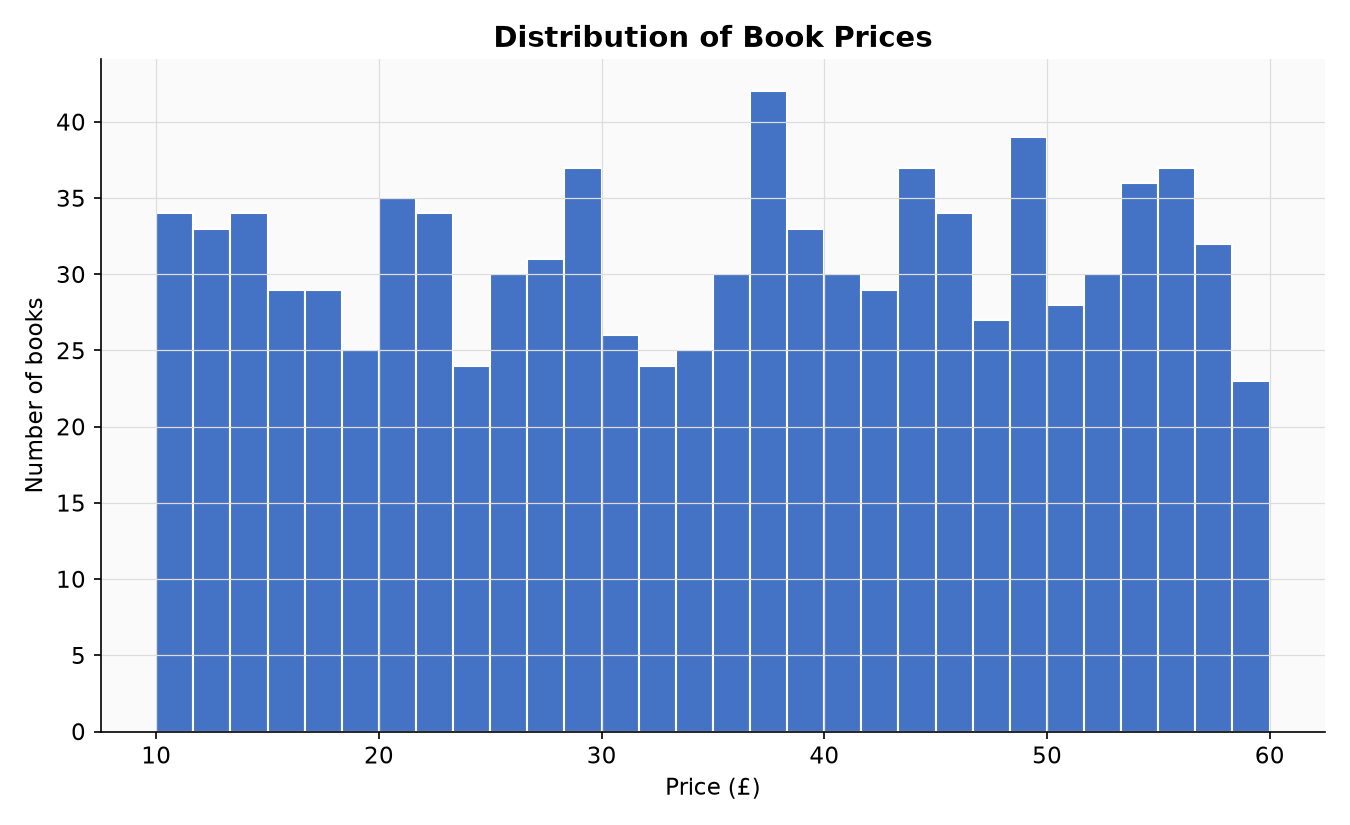

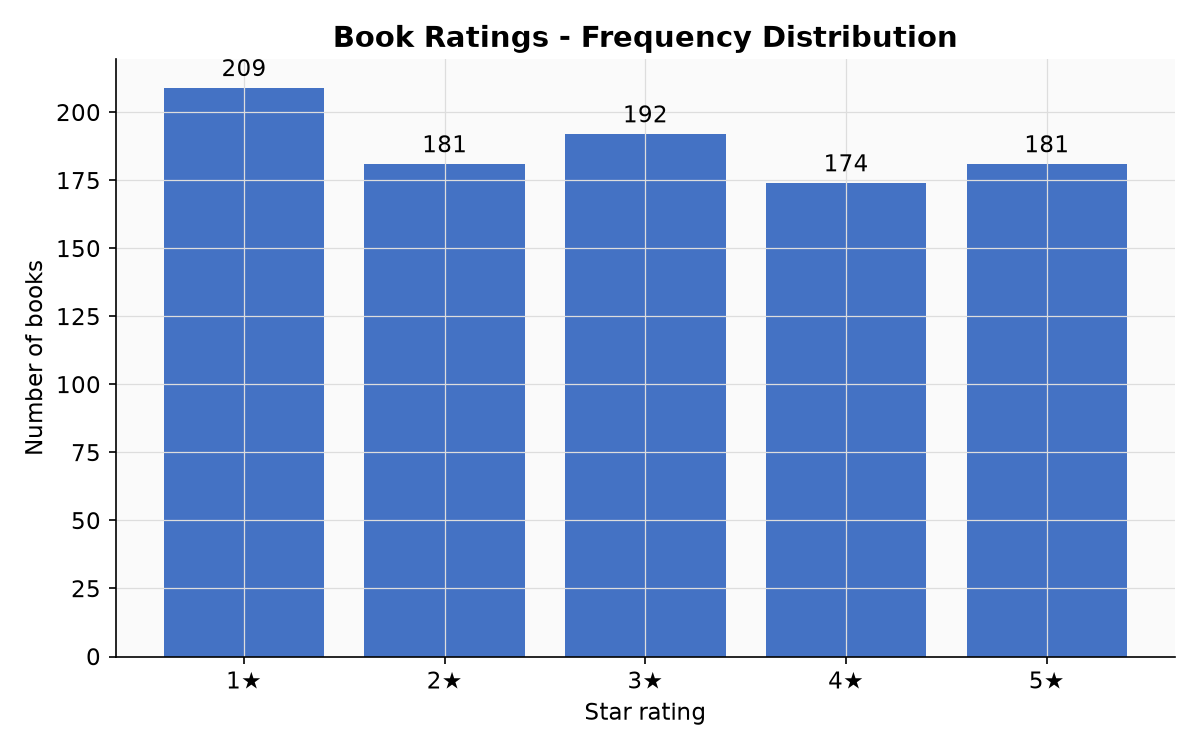

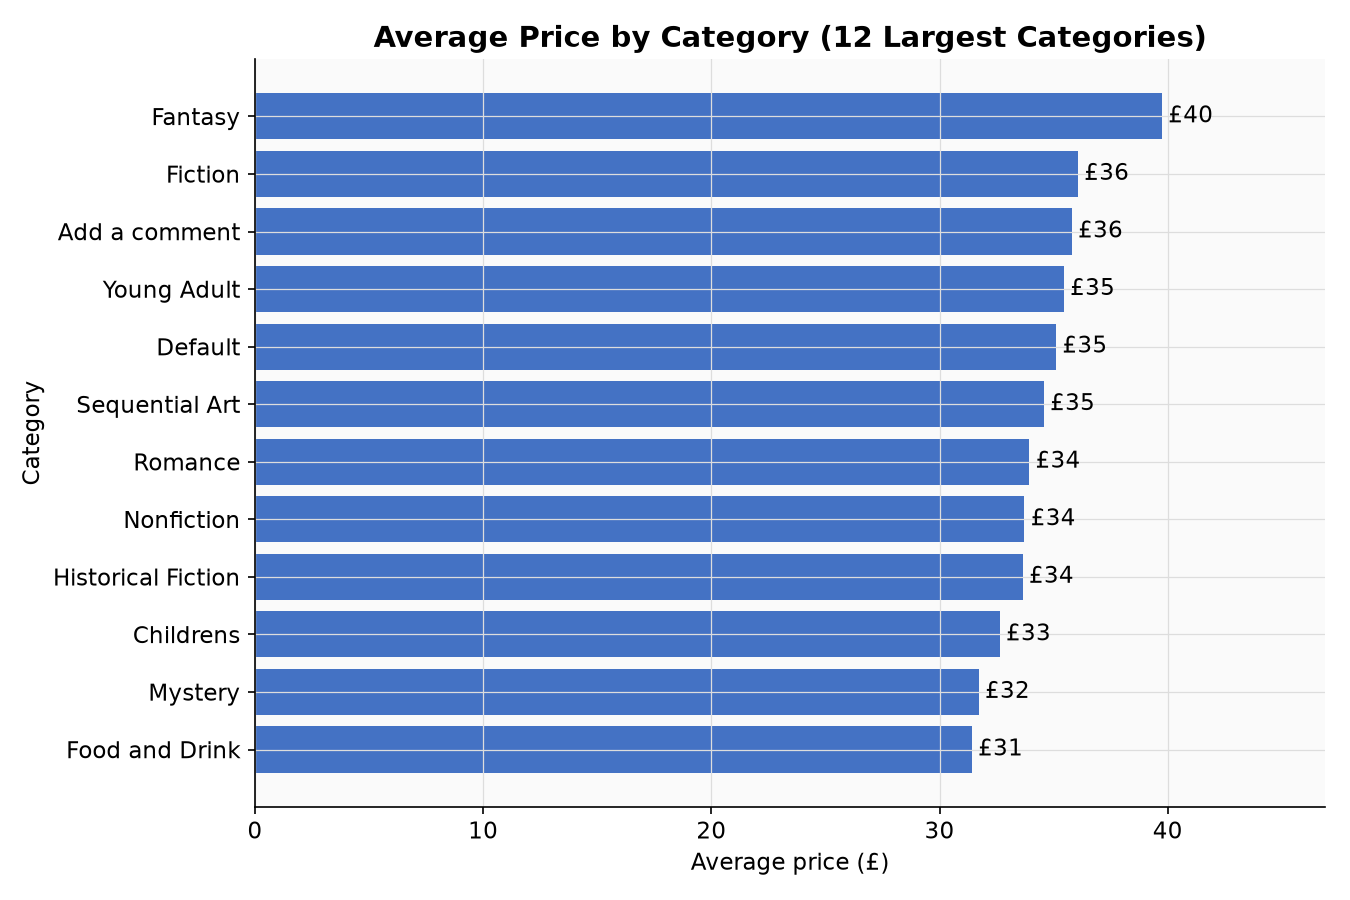

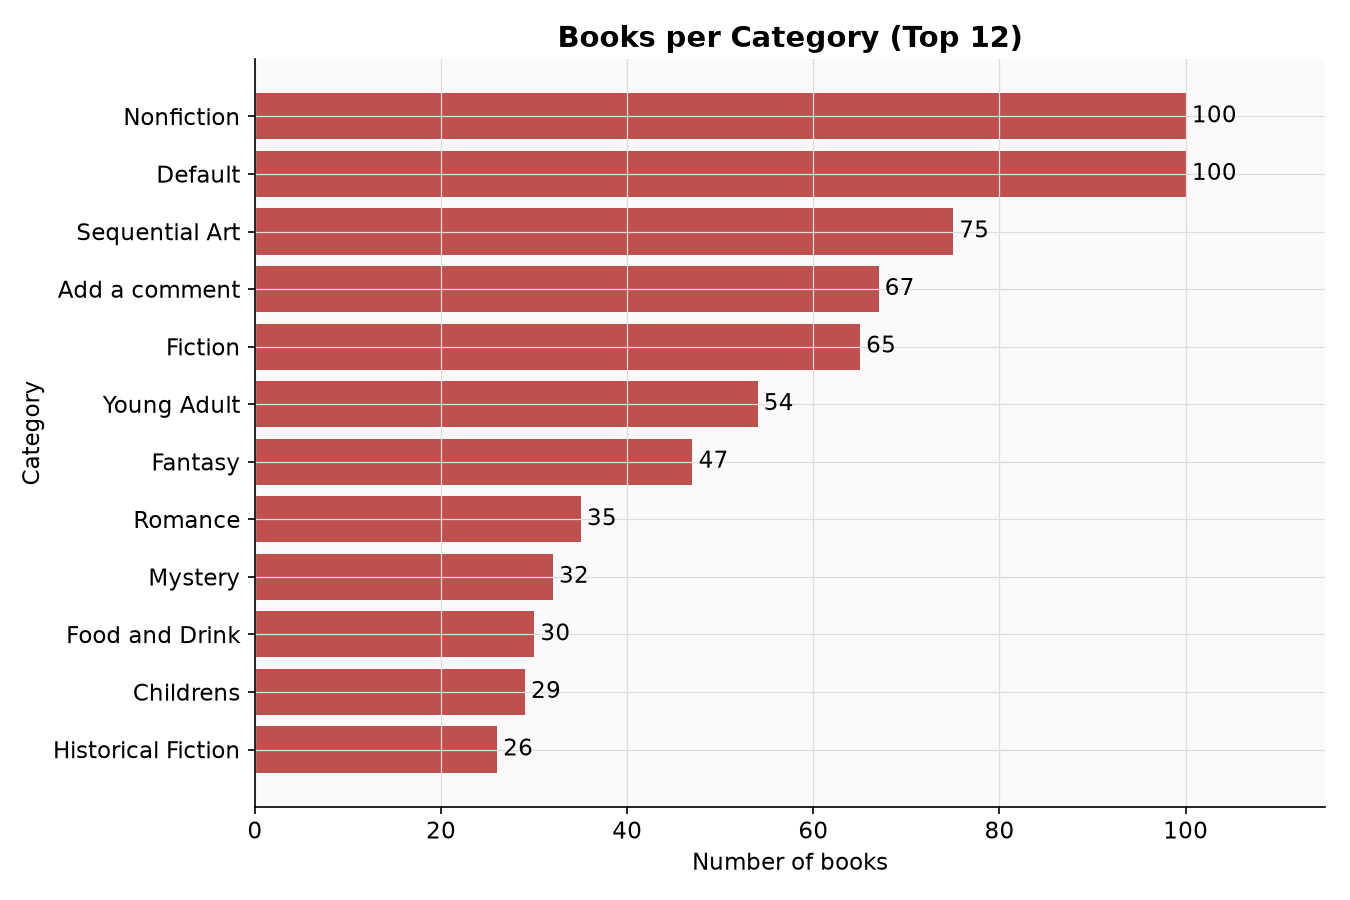

In [9]:
from IPython.display import Image, display
paths = create_all_charts(cleaned_df)
for path in paths:
    display(Image(filename=str(path)))

## 7. Conclusion

- We collected **≈1,000 unique books** across **≈50 categories** from a scraping-friendly public website.
- The pipeline handled **pagination, request errors, missing data and duplicates** automatically.
- Prices range from a few pounds to £59.99; rating and price patterns per category are visible in the charts above.

**Outputs produced by this notebook**
| File | Contents |
|---|---|
| `data/scraped_data.csv` | Raw scraped records |
| `data/cleaned_data.csv` | Cleaned dataset |
| `data/analysis_summary.txt` | Full analysis report |
| `data/category_summary.csv` | Category-wise statistics |
| `assets/*.png` | Charts (also shown above) |